# EDA NextWatch

Analyse exploratoire des données MovieLens 100k.

1. **Qu'ai-je ?** (structure)
2. **Puis-je faire confiance aux données ?** (qualité)
3. **Quels genres préfère-t-on selon l'âge et le sexe ?** (profils de genres, pas les notes)
4. **Qu'est-ce qui manque ?** (biais, limites, représentativité, causalité)


## Étape 1 — Qu'ai-je ?

Avant d'analyser les tendances, on décrit la structure du jeu de données. Cette étape précise le nombre d'observations, les variables disponibles, leurs types et les premiers ordres de grandeur.

In [82]:
from pathlib import Path

import pandas as pd

GENRES = [
    "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western",
]

# Chemins possibles selon le dossier de travail (notbook/ ou racine du projet)
_candidates = [Path("../dataset"), Path("dataset")]
DATA_DIR = next(
    (p for p in _candidates if p.is_dir() and (p / "u.data.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Dossier dataset introuvable (u.data.csv manquant).")

notes = pd.read_csv(DATA_DIR / "u.data.csv")
films = pd.read_csv(DATA_DIR / "u.item.csv")
users = pd.read_csv(DATA_DIR / "u.user.csv", dtype={"zip_code": "string"})

notes["datetime"] = pd.to_datetime(notes["timestamp"], unit="s", utc=True)
films["release_date"] = pd.to_datetime(
    films["release_date"], format="%d-%b-%Y", errors="coerce"
)
films["release_year"] = films["release_date"].dt.year

df = notes.merge(users, on="user_id", how="left").merge(
    films, left_on="item_id", right_on="movie_id", how="left"
)

print(f"df chargé : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
df.head()


df chargé : 100,000 lignes × 34 colonnes


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,...,0,0,0,0,0,0,0,0,0,1994.0
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,...,0,0,0,0,1,0,0,1,1,1994.0
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,...,0,0,0,0,0,0,0,0,0,1997.0


### 1. Aperçu

Le DataFrame `df` a déjà été chargé dans la cellule précédente. On observe ici quelques lignes et un échantillon aléatoire.


**Premières lignes :**


In [83]:
display(df.head())


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,...,0,0,0,0,0,0,0,0,0,1994.0
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,...,0,0,0,0,1,0,0,1,1,1994.0
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,...,0,0,0,0,0,0,0,0,0,1997.0


**Échantillon aléatoire :**


In [84]:
display(df.sample(5, random_state=42))


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
75721,877,381,4,882677345,1997-12-21 04:09:05+00:00,30,M,other,77504,381,...,0,0,0,0,1,0,0,0,0,1994.0
80184,815,602,3,878694269,1997-11-05 01:44:29+00:00,32,M,other,28806,602,...,0,0,1,0,1,0,0,0,0,1951.0
19864,94,431,4,891721716,1998-04-04 20:28:36+00:00,26,M,student,71457,431,...,0,0,0,0,0,0,0,0,0,1986.0
76699,416,875,2,876696938,1997-10-12 22:55:38+00:00,20,F,student,92626,875,...,0,0,0,0,1,0,0,0,0,1997.0
92991,500,182,2,883873556,1998-01-04 00:25:56+00:00,28,M,administrator,94305,182,...,0,0,0,0,0,0,0,0,0,1990.0


### 2. Dimensions et variables

`df.shape` indique le nombre de lignes et de colonnes. `df.columns` permet d'identifier les variables disponibles dans la table fusionnée.

In [85]:
print("Dimensions du DataFrame :", df.shape)


Dimensions du DataFrame : (100000, 34)


**Variables disponibles :**


In [86]:
display(pd.DataFrame({"variable": df.columns}))


,variable
0,user_id
1,item_id
2,rating
3,timestamp
4,datetime
5,age
6,gender
7,occupation
8,zip_code
9,movie_id


### 3. Types et informations générales

`df.info()` et `df.dtypes` permettent de vérifier les types des colonnes et la présence éventuelle de valeurs manquantes.

**Informations générales :**


In [87]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column              Non-Null Count   Dtype             
---  ------              --------------   -----             
 0   user_id             100000 non-null  int64             
 1   item_id             100000 non-null  int64             
 2   rating              100000 non-null  int64             
 3   timestamp           100000 non-null  int64             
 4   datetime            100000 non-null  datetime64[s, UTC]
 5   age                 100000 non-null  int64             
 6   gender              100000 non-null  str               
 7   occupation          100000 non-null  str               
 8   zip_code            100000 non-null  string            
 9   movie_id            100000 non-null  int64             
 10  title               100000 non-null  str               
 11  release_date        99991 non-null   datetime64[us]    
 12  video_release_date  0 non-null       float

**Types des variables :**


In [88]:
display(df.dtypes.rename("type").to_frame())


,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
age,int64
gender,str
occupation,str
zip_code,string
movie_id,int64


### 4. Premiers ordres de grandeur

`df.describe()` résume les variables numériques avec leur effectif, leur moyenne, leur écart-type, leurs quartiles et leurs valeurs extrêmes.

In [89]:
# Premiers ordres de grandeur sur les variables numériques
description = df.describe().T
display(description)


,count,mean,min,25%,50%,75%,max,std
user_id,100000.0,462.48475,1.0,254.0,447.0,682.0,943.0,266.61442
item_id,100000.0,425.53013,1.0,175.0,322.0,631.0,1682.0,330.798356
rating,100000.0,3.52986,1.0,3.0,4.0,4.0,5.0,1.125674
timestamp,100000.0,883528851.48862,874724710.0,879448709.5,882826944.0,888259984.0,893286638.0,5343856.189503
age,100000.0,32.96985,7.0,24.0,30.0,40.0,73.0,11.562623
movie_id,100000.0,425.53013,1.0,175.0,322.0,631.0,1682.0,330.798356
release_date,99991,1988-02-09 00:43:11.369223,1922-01-01 00:00:00,1986-01-01 00:00:00,1994-01-01 00:00:00,1996-09-28 00:00:00,1998-10-23 00:00:00,NaN
video_release_date,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unknown,100000.0,0.0001,0.0,0.0,0.0,0.0,1.0,0.01
Action,100000.0,0.25589,0.0,0.0,0.0,1.0,1.0,0.436362


### 5. Conclusion

Cette description donne le cadre de l'analyse : le DataFrame contient les évaluations, les informations utilisateurs et les informations films. Les étapes suivantes pourront donc étudier sa qualité puis les tendances observées.

In [90]:
print(f"Le jeu de données contient {df.shape[0]:,} lignes et {df.shape[1]} colonnes.")


Le jeu de données contient 100,000 lignes et 34 colonnes.


Il rassemble les notes, les utilisateurs et les films dans un même DataFrame.


## Étape 2 — Puis-je faire confiance aux données ?

La question est : **puis-je faire confiance aux données ?**

On vérifie les valeurs manquantes, les doublons, les catégories, les min/max/quantiles ainsi que la cohérence des dates, des unités et des types.


### 1. Point de départ

Le DataFrame `df` est déjà chargé (étape 1). On enchaîne directement sur les contrôles de qualité.


In [91]:
print("df déjà en mémoire — dimensions :", df.shape)
df.head()


df déjà en mémoire — dimensions : (100000, 34)


,user_id,item_id,rating,timestamp,datetime,age,gender,occupation,zip_code,movie_id,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,1997-12-04 15:55:49+00:00,49,M,writer,55105,242,...,0,0,0,0,0,0,0,0,0,1997.0
1,186,302,3,891717742,1998-04-04 19:22:22+00:00,39,F,executive,00000,302,...,1,0,0,1,0,0,1,0,0,1997.0
2,22,377,1,878887116,1997-11-07 07:18:36+00:00,25,M,writer,40206,377,...,0,0,0,0,0,0,0,0,0,1994.0
3,244,51,2,880606923,1997-11-27 05:02:03+00:00,28,M,technician,80525,51,...,0,0,0,0,1,0,0,1,1,1994.0
4,166,346,1,886397596,1998-02-02 05:33:16+00:00,47,M,educator,55113,346,...,0,0,0,0,0,0,0,0,0,1997.0


### 2. Valeurs manquantes

`df.isna().sum()` permet d'identifier les colonnes incomplètes. Le pourcentage est ajouté pour mesurer l'importance de chaque manque et décider s'il faut le traiter.


In [92]:
# Valeurs manquantes : que manque-t-il ?
missing = (
    df.isna().sum()
      .rename("n_manquants")
      .to_frame()
      .assign(pourcentage=lambda x: (100 * x["n_manquants"] / len(df)).round(2))
      .query("n_manquants > 0")
      .sort_values("n_manquants", ascending=False)
)
display(missing)


,n_manquants,pourcentage
video_release_date,100000,100.00
imdb_url,13,0.01
release_date,9,0.01
release_year,9,0.01


### 3. Doublons

On recherche les doublons sur toute la ligne et sur le couple **utilisateur-film**. Dans ce jeu de données, un même utilisateur ne doit noter un film qu'une seule fois.


In [93]:
# Doublons : y a-t-il des lignes répétées ?
duplicates = pd.DataFrame({
    "doublons_complets": [int(df.duplicated().sum())],
    "doublons_user_film": [int(df.duplicated(["user_id", "item_id"]).sum())],
})
display(duplicates)


,doublons_complets,doublons_user_film
0,0,0


### 4. Catégories et modalités

`nunique()` indique le nombre de modalités différentes et `value_counts()` leur répartition. On vérifie ainsi les valeurs étranges dans le sexe, le métier et les notes.


In [94]:
# Catégories : les valeurs sont-elles cohérentes ?
category_summary = pd.DataFrame({
    "colonne": ["gender", "occupation", "rating"],
    "nunique": [
        int(df["gender"].nunique(dropna=True)),
        int(df["occupation"].nunique(dropna=True)),
        int(df["rating"].nunique(dropna=True)),
    ],
    "valeurs": [
        ", ".join(sorted(df["gender"].dropna().astype(str).unique())),
        ", ".join(sorted(df["occupation"].dropna().astype(str).unique())),
        ", ".join(str(value) for value in sorted(df["rating"].dropna().unique())),
    ],
})
display(category_summary)
display(df["gender"].value_counts(dropna=False).rename_axis("gender").to_frame("effectif"))
display(df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").to_frame("effectif"))


,colonne,nunique,valeurs
0,gender,2,"F, M"
1,occupation,21,"administrator, artist, doctor, educator, engin..."
2,rating,5,"1, 2, 3, 4, 5"


,effectif
gender,
M,74260
F,25740


,effectif
rating,
1,6110
2,11370
3,27145
4,34174
5,21201


### 5. Min, max, quantiles et incohérences

Les statistiques descriptives permettent de repérer les valeurs impossibles ou surprenantes. Les contrôles comparent ensuite les résultats à des bornes plausibles pour les notes, les âges, les années et les timestamps.


In [95]:
# Min, max et quantiles : valeurs impossibles ou surprenantes ?
numeric_columns = ["rating", "age", "timestamp", "release_year"]
numeric_summary = df[numeric_columns].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
numeric_summary = numeric_summary[["min", "1%", "25%", "50%", "75%", "99%", "max"]]
display(numeric_summary)

range_checks = pd.DataFrame({
    "controle": [
        "notes hors de l'intervalle [1, 5]",
        "âges hors de l'intervalle plausible [1, 120]",
        "années de sortie hors [1888, année actuelle]",
        "timestamps négatifs",
        "dates converties invalides",
    ],
    "effectif": [
        int((df["rating"].notna() & ~df["rating"].between(1, 5)).sum()),
        int((df["age"].notna() & ~df["age"].between(1, 120)).sum()),
        int((df["release_year"].notna() & ~df["release_year"].between(1888, pd.Timestamp.now().year)).sum()),
        int((df["timestamp"].notna() & (df["timestamp"] < 0)).sum()),
        int(df["datetime"].isna().sum()),
    ],
})
display(range_checks)


,min,1%,25%,50%,75%,99%,max
rating,1.0,1.0,3.0,4.0,4.0,5.0,5.0
age,7.0,15.0,24.0,30.0,40.0,61.0,73.0
timestamp,874724710.0,874825826.0,879448709.5,882826944.0,888259984.0,892911494.0,893286638.0
release_year,1922.0,1939.0,1986.0,1994.0,1996.0,1997.0,1998.0


,controle,effectif
0,"notes hors de l'intervalle [1, 5]",0
1,"âges hors de l'intervalle plausible [1, 120]",0
2,"années de sortie hors [1888, année actuelle]",0
3,timestamps négatifs,0
4,dates converties invalides,0


### 6. Dates, unités et types

On vérifie les types de colonnes avec `df.dtypes` et les bornes temporelles. Le timestamp est exprimé en secondes Unix, tandis que `datetime` doit être une date exploitable.


In [96]:
# Dates, unités et types : sont-ils cohérents ?
type_summary = df.dtypes.astype(str).rename("type").to_frame()
display(type_summary)

date_summary = pd.DataFrame({
    "indicateur": [
        "timestamp min",
        "timestamp max",
        "datetime min",
        "datetime max",
        "années de sortie manquantes",
    ],
    "valeur": [
        df["timestamp"].min(),
        df["timestamp"].max(),
        df["datetime"].min(),
        df["datetime"].max(),
        int(df["release_year"].isna().sum()),
    ],
})
display(date_summary)


,type
user_id,int64
item_id,int64
rating,int64
timestamp,int64
datetime,"datetime64[s, UTC]"
age,int64
gender,str
occupation,str
zip_code,string
movie_id,int64


,indicateur,valeur
0,timestamp min,874724710
1,timestamp max,893286638
2,datetime min,1997-09-20 03:05:10+00:00
3,datetime max,1998-04-22 23:10:38+00:00
4,années de sortie manquantes,9


### 7. Conclusion

Ces contrôles ne suppriment aucune donnée automatiquement. Ils servent à documenter la qualité du jeu de données et à signaler les points à prendre en compte dans les étapes 3 et 4.

- Les valeurs manquantes, les doublons et les catégories ont été vérifiés.

- Les min, max et quantiles permettent de repérer les valeurs impossibles ou atypiques.

- Les dates, les unités et les types sont contrôlés avant les étapes 3 et 4.

- Les valeurs manquantes de release_date et release_year correspondent à des dates absentes du catalogue.


## Étape 3 — Quels genres préfère-t-on selon l'âge et le sexe ?

On ne regarde **pas** ici la note moyenne, mais le **profil de genres** :
quelle part des films notés par un groupe (sexe / âge) appartient à chaque genre.

Indicateur : pour un groupe, `part_genre = notes du genre / toutes les notes du groupe`.
Un film multi-genres compte dans chaque genre concerné.

1. Contexte (âge, sexe, catalogue)
2. Préférences de genres selon le **sexe**
3. Préférences de genres selon l'**âge**
4. Synthèse


In [97]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

users = df.drop_duplicates("user_id")
films = df.drop_duplicates("movie_id")

df["age_bin"] = pd.cut(
    df["age"],
    bins=[0, 17, 24, 34, 44, 54, 100],
    labels=["≤17", "18-24", "25-34", "35-44", "45-54", "55+"],
)

print(f"Notes : {len(df):,}  |  Utilisateurs : {len(users):,}  |  Films : {len(films):,}")


Notes : 100,000  |  Utilisateurs : 943  |  Films : 1,682


### 1. Contexte — qui note, et quels genres existent ?


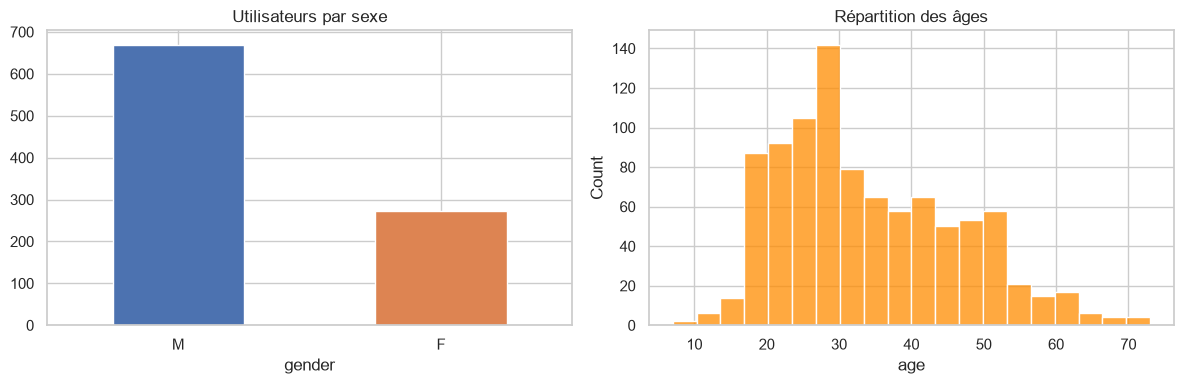

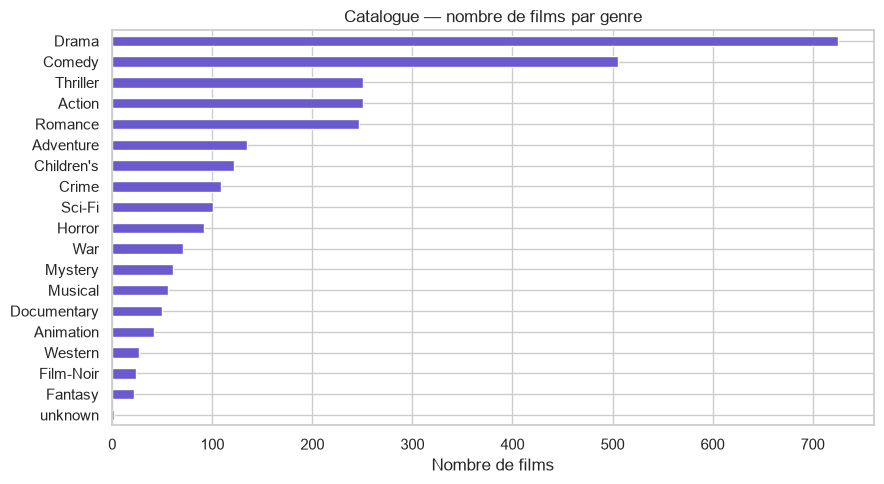

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
users["gender"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Utilisateurs par sexe")
axes[0].tick_params(axis="x", rotation=0)
sns.histplot(users["age"], bins=20, ax=axes[1], color="darkorange")
axes[1].set_title("Répartition des âges")
plt.tight_layout()
plt.show()

films[GENRES].sum().sort_values().plot(kind="barh", figsize=(9, 5), color="slateblue")
plt.title("Catalogue — nombre de films par genre")
plt.xlabel("Nombre de films")
plt.tight_layout()
plt.show()


**Lecture**

- Plus d'hommes que de femmes dans le panel ; public surtout jeune adulte.
- Le catalogue est dominé par Drama / Comedy : la « préférence » mesurée plus bas est relative
  à ce qu'on note, pas seulement à ce qui existe.


### 2. Préférences de genres selon le sexe


,F,M,ecart_F_moins_M
Romance,0.228,0.183,0.044
Drama,0.428,0.389,0.039
Comedy,0.313,0.293,0.020
Children's,0.087,0.067,0.020
Musical,0.056,0.047,0.009
Animation,0.039,0.035,0.004
Fantasy,0.014,0.013,0.001
unknown,0.000,0.000,-0.000
Documentary,0.007,0.008,-0.000
Mystery,0.051,0.053,-0.002


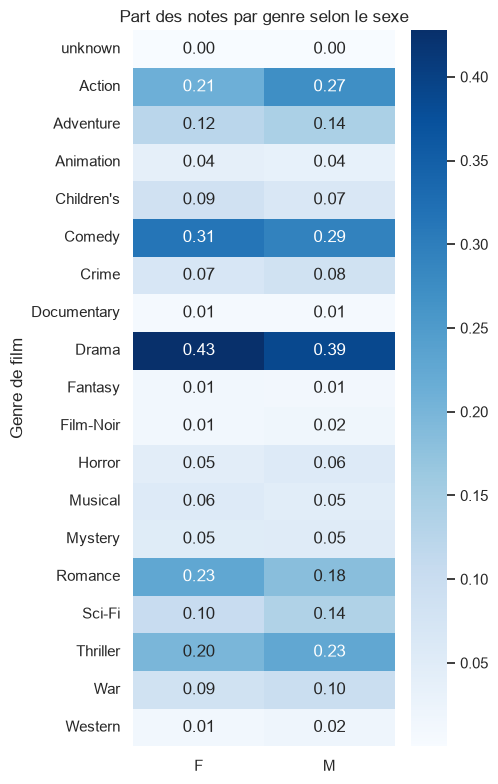

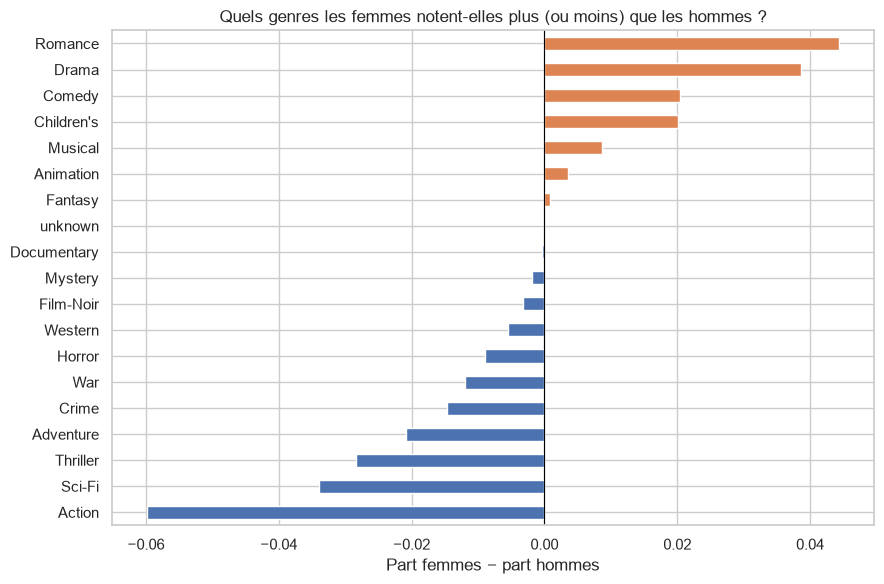

In [99]:
def preference_share(frame, group_col, genres=GENRES):
    """Part des notes d'un groupe qui touchent chaque genre."""
    out = {}
    for key, sub in frame.groupby(group_col, observed=True):
        n = len(sub)
        out[key] = {g: (sub[g] == 1).mean() for g in genres}
    return pd.DataFrame(out)

pref_gender = preference_share(df, "gender")
pref_gender["ecart_F_moins_M"] = pref_gender["F"] - pref_gender["M"]
display(pref_gender.sort_values("ecart_F_moins_M", ascending=False).round(3))

# Heatmap des parts (pas des notes)
plt.figure(figsize=(5, 8))
sns.heatmap(pref_gender[["F", "M"]], annot=True, fmt=".2f", cmap="Blues")
plt.title("Part des notes par genre selon le sexe")
plt.ylabel("Genre de film")
plt.tight_layout()
plt.show()

# Écarts : genres plus « féminins » / « masculins » en volume relatif
ecarts = pref_gender["ecart_F_moins_M"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#DD8452" if v > 0 else "#4C72B0" for v in ecarts]
ecarts.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Part femmes − part hommes")
ax.set_title("Quels genres les femmes notent-elles plus (ou moins) que les hommes ?")
plt.tight_layout()
plt.show()


**Lecture**

- La heatmap montre, pour chaque sexe, **quelle fraction de leurs notes** concerne chaque genre
  (pas s'ils mettent 4 ou 5).
- L'écart F−M : à droite / positif → genre relativement plus fréquent chez les femmes
  (ex. Romance, Drama) ; à gauche / négatif → plus fréquent chez les hommes
  (ex. Action, Sci-Fi, Thriller).
- Drama et Comedy restent élevés pour les deux : ce sont des genres très présents.


### 3. Préférences de genres selon l'âge


,≤17,18-24,25-34,35-44,45-54,55+
Drama,0.334,0.364,0.386,0.410,0.466,0.472
Comedy,0.315,0.306,0.307,0.296,0.274,0.268
Action,0.294,0.285,0.266,0.239,0.220,0.192
Thriller,0.248,0.242,0.217,0.203,0.205,0.202
Romance,0.179,0.184,0.196,0.198,0.208,0.198
Adventure,0.153,0.144,0.144,0.141,0.115,0.105
Sci-Fi,0.132,0.133,0.139,0.124,0.106,0.085
War,0.079,0.079,0.094,0.101,0.108,0.108
Crime,0.083,0.089,0.078,0.073,0.080,0.084
Children's,0.107,0.074,0.072,0.083,0.053,0.053


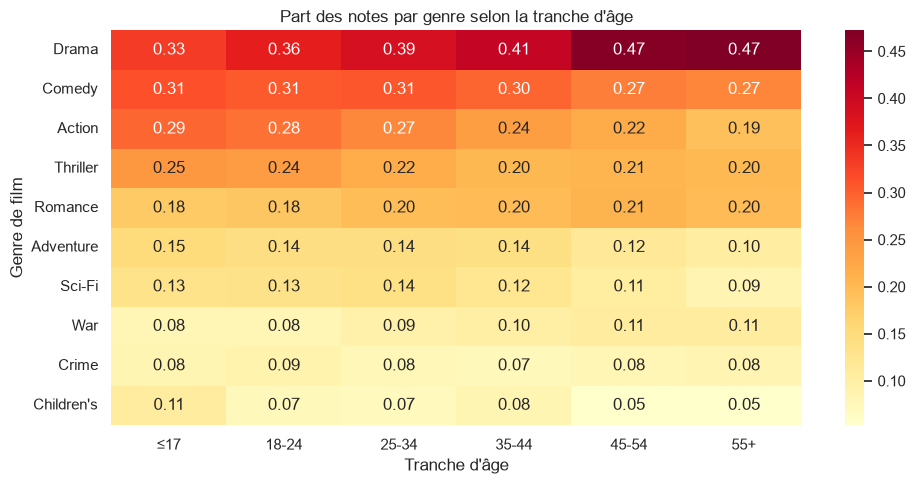

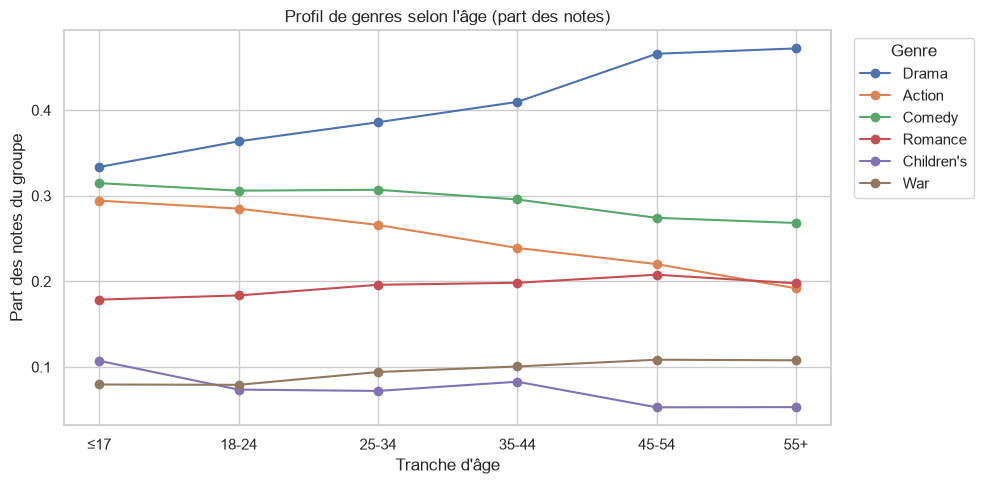

In [100]:
pref_age = preference_share(df, "age_bin")
# Garder les genres les plus « consommés » globalement pour la lisibilité
top_genres = (
    pd.Series({g: (df[g] == 1).sum() for g in GENRES})
    .sort_values(ascending=False)
    .head(10)
    .index.tolist()
)
pref_age_top = pref_age.loc[top_genres]
display(pref_age_top.round(3))

plt.figure(figsize=(10, 5))
sns.heatmap(pref_age_top, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Part des notes par genre selon la tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Genre de film")
plt.tight_layout()
plt.show()

# Évolution de quelques genres forts avec l'âge
focus = ["Drama", "Action", "Comedy", "Romance", "Children's", "War"]
pref_age.loc[focus].T.plot(marker="o", figsize=(10, 5))
plt.title("Profil de genres selon l'âge (part des notes)")
plt.ylabel("Part des notes du groupe")
plt.xlabel("Tranche d'âge")
plt.legend(title="Genre", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Lecture**

- Heatmap : plus la case est chaude, plus ce genre occupe une grande part des notes de la tranche d'âge.
- Courbes : avec l'âge, la part de **Drama** (et souvent War) augmente, tandis qu'**Action**
  et **Comedy** / **Children's** baissent plutôt chez les plus âgés.
- Encore une fois : ce sont des **goûts de choix** (quoi noter), pas des scores de satisfaction.


### 4. Synthèse

| Question | Constat |
| --- | --- |
| Femmes vs hommes : quels genres ? | Les femmes ont une part plus élevée de Romance et Drama ; les hommes d'Action, Sci-Fi et Thriller. |
| L'âge change-t-il les genres choisis ? | Oui : la part de Drama augmente avec l'âge ; Action (et Children's chez les plus jeunes) est plus présente chez les plus jeunes. |
| Attention | On mesure la **structure des notes** (exposition / intérêt), pas la note moyenne. Un genre « préféré » ici = plus souvent noté par le groupe. |


## Étape 4 — Qu'est-ce qui manque ?

L'étape 3 a décrit **quels genres** sont davantage notés selon l'âge et le sexe.
Cette étape précise **ce que l'EDA ne permet pas de conclure** : biais, limites,
représentativité et absence de causalité.

1. Biais
2. Limites des données
3. Représentativité (lien avec l'étape 3)
4. Causalité
5. Contrôles d'interprétation
6. Conclusion


### 1. Biais

- **Biais de sélection** : les utilisateurs et les films de MovieLens ne représentent ni toute la population ni l'ensemble du catalogue mondial.
- **Biais de participation** : on voit seulement ce qui est noté, pas ce qui est regardé sans note.
- **Biais de popularité / catalogue** : Drama et Comedy sont partout ; une « préférence » élevée
  pour Drama reflète aussi l'offre, pas seulement un goût intrinsèque.


### 2. Limites des données

- Le jeu contient des notes, un profil utilisateur déclaré (âge, sexe, métier) et des genres, mais **pas** :
  le contexte de visionnage, les recommandations reçues, les goûts non exprimés, ni la raison d'une note.
- Les données sont **historiques** (1997–1998) : les comportements et l'offre de films ont évolué depuis.
- Certaines modalités sont **peu représentées** (métiers rares, genres peu notés) : une moyenne
  calculée sur peu d'observations doit être lue avec prudence.
- `video_release_date` est vide ; quelques `release_date` / `release_year` manquent.


### 3. Représentativité (lien avec l'étape 3)

Les profils de genres décrivent **ce jeu MovieLens**, pas tous les spectateurs.

- Les hommes sont sur-représentés : leurs goûts (plus Action / Sci-Fi) pèsent plus dans le global.
- Les tranches d'âge n'ont pas les mêmes effectifs : une forte part Drama chez les 55+ repose sur moins d'utilisateurs.
- Un genre « préféré » = plus souvent **noté** par le groupe, pas forcément mieux noté.


### 4. Causalité

Observer qu'un groupe note plus souvent un genre **ne prouve pas** que l'âge ou le sexe
*causent* cette préférence. L'offre de films, les recommandations, la période (1997–1998) ou d'autres
facteurs non observés peuvent intervenir. L'EDA reste descriptive.


### 5. Contrôles d'interprétation

Quelques indicateurs pour rappeler l'échelle du jeu et la fragilité des petits effectifs.


Métiers les **moins** et les **plus** représentés (par volume de notes) :


In [101]:
print(f"Utilisateurs observés : {df['user_id'].nunique():,}")
print(f"Films observés        : {df['item_id'].nunique():,}")
print(f"Notes observées       : {len(df):,}")

notes_par_film = df.groupby("item_id").size()
notes_par_user = df.groupby("user_id").size()
print(f"\nFilms avec < 10 notes     : {(notes_par_film < 10).sum():,}")
print(f"Film le plus noté         : {notes_par_film.max():,} notes")
print(f"Utilisateur le plus actif : {notes_par_user.max():,} notes")

occ = (
    df.groupby("occupation")
      .agg(
          n_notes=("rating", "size"),
          note_moyenne=("rating", "mean"),
          n_users=("user_id", "nunique"),
      )
      .sort_values("n_notes")
)

display(occ.head(5).round(3))
display(occ.tail(5).round(3))


Utilisateurs observés : 943
Films observés        : 1,682
Notes observées       : 100,000

Films avec < 10 notes     : 530
Film le plus noté         : 583 notes
Utilisateur le plus actif : 737 notes


,n_notes,note_moyenne,n_users
occupation,,,
homemaker,299,3.301,7
doctor,540,3.689,7
salesman,856,3.583,12
none,901,3.779,9
lawyer,1345,3.735,12


,n_notes,note_moyenne,n_users
occupation,,,
programmer,7801,3.568,66
engineer,8175,3.541,67
educator,9442,3.671,95
other,10663,3.552,105
student,21957,3.515,196


### 6. Conclusion

L'EDA permet de **décrire** les notes MovieLens 100k et les écarts selon les genres de films,
l'âge, le sexe et le métier. Elle ne permet pas de **généraliser** à toute la population ni
d'**expliquer causalement** ces écarts.

Les résultats doivent être lus avec les biais et les effectifs en tête, surtout pour les
catégories rares et les films peu notés.
